# Voting rights after *Shelby County*

[Run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/YouWouldChooseNow/blob/main/notebooks/voting_rights_appendix.ipynb)

This notebook is supporting material for [*You Would Choose Now: Measuring America's Progress Toward Fairness and Tolerance*](https://leanpub.com/ywcn).
It goes with the *Voting rights* section of the chapter on equal opportunity.

The gap between Black and White turnout nearly closed in 2008 and 2012, when Barack Obama was on the ballot, and has reopened since.
In 2013, the Supreme Court's decision in *Shelby County v. Holder* ended the requirement that states and counties with a history of discrimination get federal approval before changing their voting rules ("preclearance").
Did the end of preclearance cause the gap to reopen?

The two events happened at about the same time, so this is hard to answer.

This notebook presents three analyses:

1. **The reopening.** How much the gap widened after 2012, in voter files and in two surveys, and how widely.
2. **Restrictions in force.** For each state and federal election since 2000, we record whether a restriction on registration or voting was in force, and compare the change in turnout, and in the gap, when a restriction took effect or ended with the change in states whose status didn't change. This is the most direct test of whether the restrictions states adopted lowered turnout or widened the gap.
3. **The end of preclearance.** *Shelby County* removed a requirement rather than imposing any particular rule, so its effect could include changes that a list of statewide restrictions misses. We replicate a published study that compares formerly covered counties with similar uncovered counties using voter files, examine how its result depends on choices made in the analysis, and extend the comparison through 2024 with survey data.


## Setup

Everything here runs with the libraries Colab provides.

In [1]:
import io
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:.1f}".format)

The data files are in the `data/voting_rights` folder of the repository.
If they're not found locally, they're downloaded from GitHub.

In [2]:
BASE_URL = "https://raw.githubusercontent.com/AllenDowney/YouWouldChooseNow/main/data/voting_rights/"
LOCAL = [Path("../data/voting_rights"), Path("data/voting_rights")]


def data_path(name: str, url: str | None = None) -> Path:
    """Local path to a data file, downloading it if necessary."""
    for d in LOCAL:
        if (d / name).exists():
            return d / name
    dest = LOCAL[1]
    dest.mkdir(parents=True, exist_ok=True)
    url = url or BASE_URL + name
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r:
        (dest / name).write_bytes(r.read())
    return dest / name

## Data

### Surveys

We use turnout by state from two surveys:

- The **Current Population Survey** (CPS) November supplement, which asks a large sample whether they voted. It's the standard source for turnout by race, but it's based on self-reports, and people report voting more often than they do.
- The **Cooperative Election Study** (CES), which matches respondents to state voter files and reports whether they actually voted. We use respondents matched to an active registration record.

Both tables give non-Hispanic Black and White turnout among citizens 18 and older, by state and year.
In the CPS, about 15--20% of respondents don't answer the voting question; the Census Bureau counts them as not voting (`rule == "census"`). We also show results with them left out (`"dropped"`).

In [3]:
cps = pd.read_csv(data_path("cps_turnout_policy.csv"))
ces = pd.read_csv(data_path("ces_turnout_policy.csv"))
cps.head()

,year,key,value,group,rule,pct,se,n
0,2000,state,AK,White,census,71.9,1.7,775
1,2000,state,AL,White,census,61.5,1.6,947
2,2000,state,AR,White,census,50.8,1.7,940
3,2000,state,AZ,White,census,58.1,1.6,1001
4,2000,state,CA,White,census,64.0,0.8,3656


Throughout this notebook, the turnout gap is White turnout minus Black turnout, in percentage points, as in the Brennan Center study, so a positive gap means Black turnout was lower, and a positive change means the gap widened.

To compare groups of states, we compute the gap **within each state** and then average across states, weighting each state by its number of Black respondents over all years.
Pooling all respondents in a group of states and then subtracting would mix in where each race lives: in some groups, most Black respondents are in a few states, while White respondents are spread across many.
The weights are fixed across years, so changes over time aren't caused by shifting weights, and states missing any year are left out.

In [4]:
def state_gaps(rates: pd.DataFrame, years: list[int]) -> pd.DataFrame:
    """White minus Black turnout by state and year, with standard errors and Black sample sizes."""
    s = rates[(rates.key == "state") & rates.year.isin(years)]
    w = s.pivot_table(index=["value", "year"], columns="group", values=["pct", "se", "n"])
    return pd.DataFrame({
        "gap": w["pct"]["White"] - w["pct"]["Black"],
        "se": np.hypot(w["se"]["Black"], w["se"]["White"]),
        "n_black": w["n"]["Black"],
    }).reset_index().rename(columns={"value": "state"})


def group_gaps(rates: pd.DataFrame, years: list[int], membership: dict) -> pd.DataFrame:
    """Gap by group and year: the mean of state gaps, weighted by Black respondents (fixed weights)."""
    g = state_gaps(rates, years)
    gap = g.pivot(index="state", columns="year", values="gap").dropna()
    se = g.pivot(index="state", columns="year", values="se").loc[gap.index]
    n = g.pivot(index="state", columns="year", values="n_black").loc[gap.index].sum(axis=1)
    rows = []
    member = gap.index.map(lambda st: membership.get(st))
    for value, states in gap.groupby(member).groups.items():
        wt = n[states] / n[states].sum()
        for y in gap.columns:
            rows.append({"group": value, "year": y,
                         "gap": (gap.loc[states, y] * wt).sum(),
                         "se": np.sqrt(((se.loc[states, y] * wt) ** 2).sum()),
                         "n_states": len(states), "n_black": int(n[states].sum())})
    return pd.DataFrame(rows)


def change(gg: pd.DataFrame, before: tuple, after: tuple) -> pd.Series:
    """Change in the gap from the mean of the `before` years to the mean of the `after` years."""
    m = gg.pivot(index="year", columns="group", values="gap")
    return m.loc[list(after)].mean() - m.loc[list(before)].mean()


PRES = [2000, 2004, 2008, 2012, 2016, 2020, 2024]
MID = [2002, 2006, 2010, 2014, 2018, 2022]

### Voter files

The most precise data on turnout by race come from voter files, the official records of who voted.
Kevin Morris and Michael Miller estimated ballots cast by race in every county after each federal election from 2008 to 2022, from nearly a billion voter-file records (details in Part 3), and shared the county estimates, along with the population data and their code, in a [replication package](https://doi.org/10.7910/DVN/XFNP4H).
We use these estimates in all three parts: added up to states in Parts 1 and 2, and by county in Part 3.

The package is a 14 MB zip file on Harvard Dataverse; we read the files we need directly from it.

In [5]:
ZIP_URL = "https://dataverse.harvard.edu/api/access/datafile/13105023"
zf = zipfile.ZipFile(data_path("replication.zip", ZIP_URL))
YEARS = [2008, 2010, 2012, 2014, 2016, 2018, 2020, 2022]


def read_member(name: str, **kw) -> pd.DataFrame:
    with zf.open(name) as f:
        return pd.read_csv(io.BytesIO(f.read()), **kw)


# estimated ballots by race, one file per state and year
frames = []
for name in zf.namelist():
    if "/temp/to_summaries_county/" in name and name.endswith(".csv"):
        frames.append(read_member(name, dtype={"GEOID_CVAP": str}, usecols=["GEOID_CVAP", "year", "race", "votes"]))
votes = pd.concat(frames)
votes = votes[votes.GEOID_CVAP.notna()]
votes["GEOID"] = votes.GEOID_CVAP.str.zfill(5)
votes = votes.pivot_table(index=["GEOID", "year"], columns="race", values="votes", aggfunc="sum")
votes = votes[["White", "Black", "Nonwhite"]].add_prefix("votes_").reset_index()
votes.head()

race,GEOID,year,votes_White,votes_Black,votes_Nonwhite
0,01001,2008,17563.8,3883.5,4087.2
1,01001,2010,14729.1,2758.7,2885.9
2,01001,2012,18359.5,4387.4,4617.5
3,01001,2014,10350.0,2011.0,2243.0
4,01001,2016,18664.9,3982.2,4586.1


Citizen voting-age population by race comes from the Census Bureau's special tabulation, using the five-year estimate that ends in each election year (2005–2009 for 2008).
As in the authors' code, Connecticut's 2022 figures come from the 2017–2021 tabulation, because the 2022 tabulation uses Connecticut's new planning regions instead of counties.

In [6]:
CVAP_VINTAGE = {2008: "2005-2009", 2010: "2006-2010", 2012: "2008-2012", 2014: "2010-2014",
                2016: "2012-2016", 2018: "2014-2018", 2020: "2016-2020", 2022: "2018-2022"}


def read_cvap(vintage: str) -> pd.DataFrame:
    c = read_member(f"replication/raw_data/cvap/CVAP_{vintage}_ACS_csv_files/County.csv", encoding="latin1")
    c.columns = c.columns.str.lower()
    c["GEOID"] = c.geoid.str[-5:]
    keep = {"Total": "total", "White Alone": "White", "Black or African American Alone": "Black"}
    c = c[c.lntitle.isin(keep)].assign(race=lambda d: d.lntitle.map(keep))
    w = c.pivot_table(index="GEOID", columns="race", values="cvap_est", aggfunc="sum")
    w["Nonwhite"] = w["total"] - w["White"]
    return w.add_prefix("cvap_").reset_index()


cvap_frames = []
for y, vintage in CVAP_VINTAGE.items():
    w = read_cvap(vintage).assign(year=y)
    if y == 2022:
        ct = read_cvap("2017-2021").assign(year=y)
        w = pd.concat([w[~w.GEOID.str.startswith("09")], ct[ct.GEOID.str.startswith("09")]])
    cvap_frames.append(w)
cvap = pd.concat(cvap_frames, ignore_index=True)

County covariates come from the American Community Survey (ACS) five-year estimates; we downloaded them from the Census API using the same variables as the authors' code, and include them in the repository.
Obama's 2012 vote share comes from the MIT Election Lab's county returns, which are in the replication package.

In [7]:
acs = pd.read_csv(data_path("acs_covariates.csv"), dtype={"GEOID": str})

pres = read_member("replication/raw_data/countypres_2000-2020.csv", dtype={"county_fips": str})
pres = pres[(pres.year == 2012) & (pres.party == "DEMOCRAT")]
ak_dem = pres.loc[pres.state == "ALASKA", "candidatevotes"].sum() / pres.loc[pres.state == "ALASKA", "totalvotes"].sum()
pres = pres[pres.county_fips.notna()].copy()
pres["GEOID"] = pres.county_fips.str.replace(r"\.0$", "", regex=True).str.zfill(5)
dem = (pres.groupby("GEOID").candidatevotes.sum() / pres.groupby("GEOID").totalvotes.first()).rename("dem")

covered_counties = set(read_member("replication/raw_data/counties_covered_sec5.csv", dtype=str)["county"].str.zfill(5))
FULLY_COVERED = {"01", "02", "04", "13", "22", "28", "45", "48", "51"}  # AL AK AZ GA LA MS SC TX VA
PARTLY_COVERED = {g[:2] for g in covered_counties} - FULLY_COVERED   # CA FL MI NY NC SD

Now we assemble the panel: one row per county and election.
Turnout is capped at 1, as in the authors' code (estimated ballots occasionally exceed estimated CVAP in small counties).

In [8]:
panel = (votes.merge(cvap, on=["GEOID", "year"], how="left")
              .merge(acs, on=["GEOID", "year"], how="left")
              .merge(dem, left_on="GEOID", right_index=True, how="left"))
panel.loc[panel.GEOID.str.startswith("02"), "dem"] = ak_dem
# Shannon County, SD, was renamed Oglala Lakota (46113 -> 46102) in 2015
panel = panel[(panel.GEOID != "46113") | (panel.year < 2016)]
panel["GEOID"] = panel.GEOID.replace({"46102": "46113"})
panel = panel[panel.population.notna()].copy()

panel["state"] = panel.GEOID.str[:2]
panel["covered"] = panel.state.isin(FULLY_COVERED | PARTLY_COVERED)
for r in ["White", "Black", "Nonwhite"]:
    panel[f"turnout_{r}"] = np.minimum(panel[f"votes_{r}"] / panel[f"cvap_{r}"], 1)
panel["gap"] = panel.turnout_White - panel.turnout_Nonwhite        # White minus nonwhite
panel["gap_black"] = panel.turnout_White - panel.turnout_Black     # White minus Black
panel["black_population"] = panel.nh_black * panel.population
panel["nonwhite_population"] = (1 - panel.nh_white) * panel.population
panel.groupby("year").GEOID.count()

year
2008    3136
2010    3143
2012    3143
2014    3142
2016    3142
2018    3142
2020    3143
2022    3143
Name: GEOID, dtype: int64

The `gap` columns are proportions; in the tables below they're converted to points.

## Part 1: The reopening

The gap between White and Black turnout, nationally, from each source.
For the surveys, it's the average of state gaps, computed as above with all states in one group, with fixed weights; for the voter files, it's all White ballots over all White citizens of voting age, minus the same for Black, so each state counts in proportion to its population in that year.
The two kinds of series aren't computed identically, so their levels aren't directly comparable, but their changes over time are.

In [9]:
everywhere = {st: "all states" for st in cps.loc[cps.key == "state", "value"].unique()}
national_cps = group_gaps(cps[cps.rule == "census"], sorted(PRES + MID), everywhere).set_index("year").gap
national_ces = group_gaps(ces, list(range(2008, 2026, 2)), everywhere).set_index("year").gap
VF_COLS = ["votes_White", "cvap_White", "votes_Black", "cvap_Black"]
tot = panel.groupby("year")[VF_COLS].sum()
national_vf = 100 * (tot.votes_White / tot.cvap_White - tot.votes_Black / tot.cvap_Black)
national = pd.DataFrame({"voter files": national_vf, "CPS": national_cps, "CES (validated)": national_ces})
national.T

year,2000,2002,2004,2006,2008,2010,2012,2014,2016,2018,2020,2022,2024
voter files,NaN,NaN,NaN,NaN,3.4,8.3,1.3,7.9,8.8,8.6,10.9,15.8,NaN
CPS,4.9,5.8,6.2,7.9,1.3,3.6,-2.4,4.3,5.4,5.4,7.7,10.7,10.4
CES (validated),NaN,NaN,NaN,NaN,-1.2,10.3,2.6,18.4,8.7,11.4,9.6,16.4,8.3


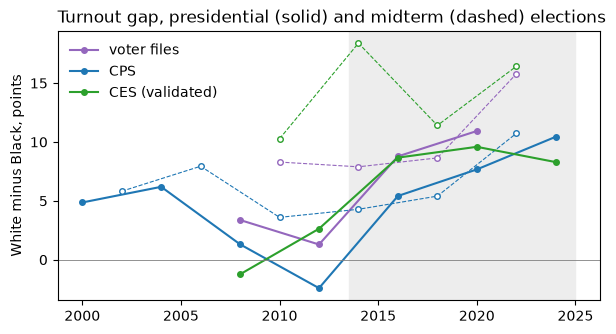

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for (name, color) in [("voter files", "C4"), ("CPS", "C0"), ("CES (validated)", "C2")]:
    s = national[name].dropna()
    ax.plot([y for y in PRES if y in s.index], s.reindex([y for y in PRES if y in s.index]),
            marker="o", ms=4, color=color, label=name)
    ax.plot([y for y in MID if y in s.index], s.reindex([y for y in MID if y in s.index]),
            marker="o", ms=4, mfc="white", ls="--", lw=0.8, color=color)
ax.axhline(0, color="0.5", lw=0.6)
ax.axvspan(2013.5, 2025, color="0.93", zorder=0)
ax.set_title("Turnout gap, presidential (solid) and midterm (dashed) elections", loc="left")
ax.set_ylabel("White minus Black, points")
ax.legend(frameon=False);

In all three sources the gap was smallest in 2012 and has grown since.
In the voter files, it went from 1.3 points in 2012 to 10.9 in 2020, and from 8.3 in the 2010 midterm to 15.8 in 2022.
In the CPS, it went from −2.4 in 2012 (Black turnout was higher) to 7.7 in 2020 and 10.4 in 2024, wider than before Obama's campaigns (5 to 6 points in 2000 and 2004).
Midterm gaps are wider than presidential gaps in every source.
The CES gaps jump around more, because its state samples are small.

How widely?
In the voter files, here are the states with at least 100,000 Black citizens of voting age in 2012, and the change in each state's gap from 2012 to 2020 (presidential elections) and from 2010 to 2022 (midterms).

In [11]:
by_state = panel.groupby(["state", "year"])[VF_COLS].sum()
state_gap = (100 * (by_state.votes_White / by_state.cvap_White - by_state.votes_Black / by_state.cvap_Black)).unstack("year")
big = by_state.cvap_Black.xs(2012, level="year") >= 100_000
spread = pd.DataFrame({"2012 to 2020": state_gap[2020] - state_gap[2012],
                       "2010 to 2022": state_gap[2022] - state_gap[2010]})[big]
print(len(spread), "states;", "widened in", (spread > 0).sum().to_dict())
spread.describe().loc[["min", "50%", "max"]]

34 states; widened in {'2012 to 2020': 34, '2010 to 2022': 34}


,2012 to 2020,2010 to 2022
min,3.3,2.4
50%,8.4,6.2
max,17.6,14.4


The gap widened in every one of these 34 states, in both comparisons: by 3 to 18 points from 2012 to 2020 (median 8), and by 2 to 14 points from 2010 to 2022 (median 6).


## Part 2: Elections with and without restrictions in force

After *Shelby County*, some states adopted photo ID requirements, cut early voting or same-day registration, limited mail voting, or purged voter rolls more aggressively; some had done so before 2013, and some states made voting easier.
If restrictions widened the gap, it should change when a state's rules change.
So for each state and each federal general election from 2000 to 2024, we record whether a restriction was in force, and ask whether the gap changed when a state's status changed -- when a restriction took effect, or when it was blocked or repealed -- relative to states whose status didn't change.

The measures are in `state_election_measures.csv`, one row per law or rule, with the first and last federal general election it was in force for.
They were compiled from statutes, court opinions, state election offices, NCSL and the Brennan Center; the dates that determine whether a state counts as restricted were checked against primary sources where possible.

In [12]:
measures = pd.read_csv(data_path("state_election_measures.csv"))
measures[["state", "category", "description", "first_election", "last_election", "strength", "id_type"]].head()

,state,category,description,first_election,last_election,strength,id_type
0,AK,avr,Automatic registration via Permanent Fund Divi...,2018.0,NaN,expansion,NaN
1,AK,no_excuse_absentee,No-excuse absentee voting by mail and in perso...,2000.0,NaN,expansion,NaN
2,AK,photo_id,Non-photo ID required at polls (photo or non-p...,2000.0,NaN,weak,non_photo
3,AL,id_offices,2015 plan to close or cut hours at 31 driver l...,2016.0,2016.0,substantial,NaN
4,AL,mail_limits,"SB 1 (2024): crime to pay or be paid for, or t...",2024.0,NaN,weak,NaN


A state counts as restricted in an election if a substantial restriction is in force for that election.
If every restriction is blocked or repealed, the state's next election counts as unrestricted.
Photo ID laws are the hard case: many let a voter without ID sign an affidavit or declaration instead.
We use two rules, chosen before looking at turnout:

- **broad** (primary): any photo ID requirement counts, with or without an affidavit option;
- **strict**: only strict photo ID counts (a voter without ID has to take a further step after the election for the ballot to count).

Non-photo ID requirements count under neither rule.

In [13]:
RESTRICTION_CATS = {"photo_id", "early_or_sdr", "mail_limits", "purges", "id_offices", "proof_of_citizenship",
                    "closures"}
ELECTIONS = list(range(2000, 2026, 2))


def in_force(measures, rule):
    """State x election: 1 if a counted restriction is in force, else 0."""
    r = measures[measures.category.isin(RESTRICTION_CATS) & measures.first_election.notna()]
    photo = r.id_type.isin(["strict_photo", "photo_affidavit"]) if rule == "broad" else r.id_type.eq("strict_photo")
    is_id = r.category == "photo_id"
    r = r[(~is_id & (r.strength == "substantial")) | (is_id & (photo | ((r.strength == "substantial") & r.id_type.isna())))]
    status = pd.DataFrame(0, index=sorted(measures.state.unique()), columns=ELECTIONS)
    for row in r.itertuples():
        last = row.last_election if pd.notna(row.last_election) else ELECTIONS[-1]
        status.loc[row.state, [y for y in ELECTIONS if row.first_election <= y <= last]] = 1
    return status


def switch_list(status):
    """Elections in which a state's status changed."""
    d = status.diff(axis=1).iloc[:, 1:].stack()
    d = d[d != 0]
    return pd.DataFrame({"state": d.index.get_level_values(0), "election": d.index.get_level_values(1),
                         "direction": np.where(d > 0, "on", "off")})


for rule in ["broad", "strict"]:
    sw = switch_list(in_force(measures, rule))
    for direction in ["on", "off"]:
        s = sw[sw.direction == direction]
        print(f"{rule:6s} {direction:3s}", " ".join(f"{st} {y}" for st, y in zip(s.state, s.election)))

broad  on  AL 2014 AR 2018 AZ 2006 GA 2008 IA 2018 ID 2010 IN 2006 KS 2012 KY 2020 MI 2008 MO 2022 MS 2014 NC 2014 NC 2024 NE 2024 NH 2014 RI 2014 SC 2014 SD 2004 TN 2012 TX 2014 VA 2014 WI 2012 WY 2024
broad  off NC 2016 VA 2020
strict on  AL 2016 AR 2022 AZ 2006 FL 2012 FL 2022 GA 2008 IA 2018 IN 2006 KS 2012 MS 2014 NC 2014 NC 2024 SC 2022 TN 2012 TX 2014 TX 2022 VA 2014 WI 2012 WY 2024
strict off AL 2018 FL 2002 FL 2014 NC 2016 TX 2016 VA 2020


Restrictions in force in 2000 (Florida, Louisiana and Ohio, for example) aren't switches; those states serve as comparisons while their status stays the same.

The estimator is de Chaisemartin and D'Haultfœuille's difference-in-differences for treatments that switch on and off ([2020](https://doi.org/10.1257/aer.20181169)).
For each pair of consecutive elections, it compares:

- states where a restriction took effect with states unrestricted in both elections;
- states where restrictions ended with states restricted in both elections.

Each comparison is the difference between the two groups' changes in the outcome; the estimate averages them, weighted by the switching states' weight.
We apply it first to turnout and then to the turnout gap.

As a placebo, the same comparison is applied to the change from the election before: for states that switched between elections *t* − 1 and *t*, and comparison states, all with the same status in *t* − 2 and *t* − 1, the change from *t* − 2 to *t* − 1 should be near zero if switching and non-switching states were moving in parallel.
Uncertainty comes from a bootstrap over states.

In [14]:
def did_m(G, D, w, lag=0):
    """G: states x consecutive elections, gap; D: status (0/1); w: state weights. lag=1: placebo."""
    num, tot = 0.0, 0.0
    for j in range(1 + lag, G.shape[1]):
        dy = G[:, j - lag] - G[:, j - 1 - lag]
        ok = np.isfinite(dy) & (w > 0) & np.all(D[:, j - 1 - lag:j] == D[:, [j - 1]], axis=1)
        groups = {(a, b): ok & (D[:, j - 1] == a) & (D[:, j] == b) for a in (0, 1) for b in (0, 1)}

        def wm(mask):
            return (w[mask] * dy[mask]).sum() / w[mask].sum()

        on, off = groups[(0, 1)], groups[(1, 0)]
        if on.any() and groups[(0, 0)].any():
            num += w[on].sum() * (wm(on) - wm(groups[(0, 0)]))
            tot += w[on].sum()
        if off.any() and groups[(1, 1)].any():
            num += w[off].sum() * (wm(groups[(1, 1)]) - wm(off))
            tot += w[off].sum()
    return num / tot if tot else np.nan


def did_switching(gap, weight, years, status, reps=500, seed=17):
    G = gap.reindex(columns=years).to_numpy(float)
    D = status.reindex(index=gap.index, columns=years).fillna(0).to_numpy(int)
    w = weight.reindex(gap.index).fillna(0).to_numpy(float)
    rng = np.random.default_rng(seed)
    n = len(w)
    draws = []
    for _ in range(reps):
        wb = w * np.bincount(rng.integers(0, n, n), minlength=n)
        draws.append((did_m(G, D, wb), did_m(G, D, wb, lag=1)))
    draws = np.array(draws)
    sw = switch_list(status.reindex(index=gap.index, columns=years).fillna(0))
    return pd.Series({"estimate": did_m(G, D, w), "se": np.nanstd(draws[:, 0], ddof=1),
                      "placebo": did_m(G, D, w, lag=1), "placebo se": np.nanstd(draws[:, 1], ddof=1),
                      "switches on": (sw.direction == "on").sum(), "switches off": (sw.direction == "off").sum(),
                      "states": len(gap)})

### Effects on turnout

Before turning to the gap, we ask whether restrictions reduced turnout at all.
The primary measure is official: total ballots counted in each state's general election, divided by citizens of voting age, from Michael McDonald's [state turnout files](https://election.lab.ufl.edu/voter-turnout/) (University of Florida Election Lab, CC BY 4.0).
The 2024 figures are his estimates as of March 2026, before every state's results were final.
Before 2010, some states didn't report total ballots counted; those state-years are left out of the comparisons that involve them, rather than filled in with a different count.
States are weighted by citizens of voting age in 2012.
As checks, we use McDonald's voting-eligible population as the denominator (it also leaves out people disenfranchised by felony convictions), and turnout of all citizens in the CPS.

In [15]:
official = pd.read_csv(data_path("state_turnout_official.csv"))
official.head()

,state,year,ballots,vap,noncitizen_pct,vep,cvap,turnout_cvap,turnout_vep
0,AK,2000,287825.0,440296,3.4,418238,425326.0,67.7,68.8
1,AK,2002,232852.0,457154,3.8,431836,439782.0,52.9,53.9
2,AK,2004,314502.0,476378,4.0,449083,457323.0,68.8,70.0
3,AK,2006,238307.0,492452,4.5,461202,470292.0,50.7,51.7
4,AK,2008,327341.0,507645,3.7,479628,488862.0,67.0,68.2


We also estimate the effect on Black and White turnout separately, from the voter files (weighted by each group's CVAP in 2012) and from the two surveys (weighted by each group's respondents, states with at least 20 respondents in the group in every year).

In [16]:
def survey_turnout(rates, group, years, min_n=20):
    s = rates[(rates.key == "state") & rates.year.isin(years) & (rates.group == group)]
    pct = s.pivot(index="value", columns="year", values="pct")
    n = s.pivot(index="value", columns="year", values="n").reindex(columns=years).fillna(0)
    keep = (n >= min_n).all(axis=1)
    return pct[keep], n[keep].sum(axis=1)


FIPS_ABBR = {"01": "AL", "02": "AK", "04": "AZ", "05": "AR", "06": "CA", "08": "CO", "09": "CT", "10": "DE",
             "11": "DC", "12": "FL", "13": "GA", "15": "HI", "16": "ID", "17": "IL", "18": "IN", "19": "IA",
             "20": "KS", "21": "KY", "22": "LA", "23": "ME", "24": "MD", "25": "MA", "26": "MI", "27": "MN",
             "28": "MS", "29": "MO", "30": "MT", "31": "NE", "32": "NV", "33": "NH", "34": "NJ", "35": "NM",
             "36": "NY", "37": "NC", "38": "ND", "39": "OH", "40": "OK", "41": "OR", "42": "PA", "44": "RI",
             "45": "SC", "46": "SD", "47": "TN", "48": "TX", "49": "UT", "50": "VT", "51": "VA", "53": "WA",
             "54": "WV", "55": "WI", "56": "WY"}
agg = (panel.assign(st=panel.state.map(FIPS_ABBR))
            .groupby(["st", "year"])[["votes_White", "cvap_White", "votes_Black", "cvap_Black"]].sum())


def official_turnout(column):
    rate = official.pivot(index="state", columns="year", values=column)
    return rate, official[official.year == 2012].set_index("state").cvap


cps_census = cps[cps.rule == "census"]
VF_YEARS = list(range(2008, 2024, 2))
CES_YEARS = list(range(2008, 2026, 2))
TURNOUT = {
    ("all citizens", "official / CVAP"): (*official_turnout("turnout_cvap"), ELECTIONS),
    ("all citizens", "official / VEP"): (*official_turnout("turnout_vep"), ELECTIONS),
    ("all citizens", "CPS"): (*survey_turnout(cps_census, "All", ELECTIONS), ELECTIONS),
}
for group in ["Black", "White"]:
    TURNOUT[(group, "voter files")] = ((100 * agg[f"votes_{group}"] / agg[f"cvap_{group}"]).unstack("year"),
                                       agg[f"cvap_{group}"].xs(2012, level="year"), VF_YEARS)
    TURNOUT[(group, "CPS")] = (*survey_turnout(cps_census, group, ELECTIONS), ELECTIONS)
    TURNOUT[(group, "CES")] = (*survey_turnout(ces, group, CES_YEARS), CES_YEARS)

turnout_effects = pd.DataFrame({(*k, rule): did_switching(rate, w, years, in_force(measures, rule))
                                for rule in ["broad", "strict"] for k, (rate, w, years) in TURNOUT.items()}).T
turnout_effects.index.names = ["turnout of", "source", "rule"]
turnout_effects.astype({"switches on": int, "switches off": int, "states": int})

estimate  se  placebo  placebo se  switches on  switches off  states
turnout of   source          rule                                                                        
all citizens official / CVAP broad        0.1 1.0      1.4         1.2           24             2      51
             official / VEP  broad        0.1 1.0      1.4         1.2           24             2      51
             CPS             broad       -1.0 1.0      2.8         1.1           24             2      51
Black        voter files     broad       -1.9 1.6      2.8         2.6           16             2      51
             CPS             broad       -1.4 1.7      2.8         2.0           19             2      38
             CES             broad       -4.0 4.8     10.9         8.4            9             2      20
White        voter files     broad       -0.7 0.8      1.5         1.8           16             2      51
             CPS             broad       -0.9 1.1      2.3         1.2           24             2      51
             CES             broad       -0.9 1.7      6.5         6.3           19             2      50
all citizens official / CVAP strict       0.2 1.0      0.0         1.2           19             6      51
             official / VEP  strict       0.2 1.0      0.1         1.2           19             6      51
             CPS             strict      -0.9 0.7      1.1         1.3           19             6      51
Black        voter files     strict       0.0 1.5      1.1         2.3           14             5      51
             CPS             strict      -1.9 1.5      1.8         2.0           17             6      38
             CES             strict      -0.5 4.2      6.0         6.5           12             5      20
White        voter files     strict       0.3 0.8      0.8         1.5           14             5      51
             CPS             strict      -1.1 0.9      0.7         1.1           19             6      51
             CES             strict      -1.0 2.6      4.6         5.7           16             5      50

Estimates are in percentage points of turnout: how much higher turnout was with a restriction in force than without, compared with states whose status didn't change, so a negative estimate means restrictions lowered turnout.

In the official counts, the effect on overall turnout is close to zero under both rules: +0.1 points (SE 1.0) under the broad rule and +0.2 under the strict rule, which rules out declines much larger than 2 points.
The voting-eligible population gives the same result.
In the CPS, the estimates are about −1 point (SE 0.7 to 1.0); the CPS is based on self-reports, and its state samples are smaller.

Under the broad rule, the placebos are positive: +1.4 points in the official counts (SE 1.2) and +2.8 in the CPS (SE 1.1).
That means that in the election before a restriction took effect, turnout in those states had risen more than in the comparison states, so the two groups weren't moving exactly in parallel.
If that rise was temporary, it would push the estimates down, so it's unlikely that the estimates near zero hide a large decline; but it's a reason not to read much into differences of a point or two.
Under the strict rule, the placebos are close to zero.

For Black and White turnout separately, the estimates are within about 2 points of zero in the voter files and the CPS, with standard errors of 1 to 2 points for Black turnout; the CES is too small to say much.
Under the broad rule, the estimate for Black turnout is somewhat more negative than for White turnout (−1.9 and −0.7 in the voter files), which is consistent with the small effect on the gap below; under the strict rule, both are close to zero.
Because the two groups are weighted differently, the difference between them isn't exactly the estimate for the gap.

### Effects on the gap

We apply the same estimator to three sources of state gaps (White minus Black, in points):

- the voter-file estimates, added up to states (all White ballots over all White CVAP, minus the same for Black), 2008–2022, weighted by Black CVAP;
- the CPS, 2000–2024, states with at least 20 Black respondents in every year, weighted by Black respondents;
- the CES, 2008–2024, with the same rule (only 20 states qualify).

In [17]:
def survey_state_gaps(rates, years, min_black=20):
    s = rates[(rates.key == "state") & rates.year.isin(years)]
    w = s.pivot_table(index=["value", "year"], columns="group", values=["pct", "n"])
    gap = (w["pct"]["White"] - w["pct"]["Black"]).unstack("year")
    n = w["n"]["Black"].unstack("year").reindex(columns=years).fillna(0)
    keep = (n >= min_black).all(axis=1)
    return gap[keep], n[keep].sum(axis=1)


vf_gap = (100 * (agg.votes_White / agg.cvap_White - agg.votes_Black / agg.cvap_Black)).unstack("year")
vf_w = agg.cvap_Black.xs(2012, level="year")

SOURCES = {
    "voter files": (vf_gap, vf_w, list(range(2008, 2024, 2))),
    "CPS": (*survey_state_gaps(cps[cps.rule == "census"], ELECTIONS), ELECTIONS),
    "CES": (*survey_state_gaps(ces, list(range(2008, 2026, 2))), list(range(2008, 2026, 2))),
}
summary3 = pd.DataFrame({(name, rule): did_switching(gap, w, years, in_force(measures, rule))
                         for rule in ["broad", "strict"] for name, (gap, w, years) in SOURCES.items()}).T
summary3.astype({"switches on": int, "switches off": int, "states": int})

,,estimate,se,placebo,placebo se,switches on,switches off,states
voter files,broad,0.7,0.9,-0.4,1.1,16,2,51
CPS,broad,-0.5,1.5,-0.6,1.7,19,2,38
CES,broad,2.0,4.2,0.5,3.4,9,2,20
voter files,strict,0.3,0.8,0.2,0.8,14,5,51
CPS,strict,-0.2,1.6,-0.1,2.1,17,6,38
CES,strict,-0.6,3.0,0.1,3.9,12,5,20


Estimates are in points: how much wider the gap was with a restriction in force than without, compared with states whose status didn't change.
The voter files, the most precise source, put it at less than a point, with a standard error of about 1 -- enough to rule out effects much larger than 2.5 points, but not effects of a point or so.
The CPS agrees, with more uncertainty; the CES samples are too small to say much.
The rule for photo ID doesn't change this, and the placebos are near zero.

Most of the information comes from restrictions taking effect.
Under the broad rule, only two states switched off -- North Carolina, when its 2013 law was struck down before the 2016 election, and Virginia, which repealed its photo ID requirement before 2020 -- so the data say little about what happens when restrictions end.

Three limits:

- states don't restrict voting at random: adoption follows party control;
- a statewide average can miss effects concentrated in some places or offset by mobilization;
- each comparison is between the election before a switch and the election after, so an effect that builds up over several elections would be understated.

## Part 3: The end of preclearance

Part 2 asks whether specific statewide restrictions changed the gap.
The question about *Shelby County* is broader: preclearance also applied to changes that our list of restrictions doesn't record, such as closing or moving polling places, redrawing district lines, and changes made by counties and cities.
So we also compare places that lost preclearance with places that never had it.

### Counties: the published study

Kevin Morris and Michael Miller, ["Did *Shelby County v. Holder* Increase the Racial Turnout Gap?"](https://doi.org/10.1086/739960) (*Journal of Politics*, 2025), with an earlier version as a Brennan Center report by Morris and Coryn Grange, [*Growing Racial Disparities in Voter Turnout, 2008–2022*](https://www.brennancenter.org/our-work/research-reports/growing-racial-disparities-voter-turnout-2008-2022) (2024).

- **Data.** Voter files for every state after each federal election from 2008 to 2022 -- nearly a billion records -- from two commercial vendors. Where states record race (Alabama, Florida, Georgia, Louisiana, North Carolina and South Carolina), they use it; elsewhere they estimate it from surnames and neighborhoods (BISG). Turnout is ballots cast by each group divided by its citizen voting-age population (CVAP), by county.
- **Design.** Difference-in-differences. Formerly covered counties (including every county in a partly covered state, since statewide changes needed preclearance) are compared with uncovered counties, reweighted by entropy balancing to resemble covered counties in 2012 on population, racial composition, income, age, education and Obama's vote share.
- **Headline.** "By 2022, our primary models indicate that the white–Black turnout gap in these regions was about 5 percentage points greater than it would have been if the Voting Rights Act were still in full force." The main estimate in the paper averages the effect over 2014–2022: 2.8 points.

The authors shared county-level estimates of ballots by race, the CVAP files and their code ([replication package](https://doi.org/10.7910/DVN/XFNP4H)), but not the voter files.
The county panel built from those files is in the Data section; here we reproduce their estimates, and then ask how much the result depends on choices made in the analysis.

### Entropy balancing and the estimator

Formerly covered counties differ from the rest of the country: in the paper's data, the average covered county was 17% Black, compared with 3% for uncovered counties.
To make a fair comparison, the authors reweight uncovered counties so that their weighted averages match the covered counties on seven 2012 characteristics: log population, share non-Hispanic White, share non-Hispanic Black, median income, median age, share with a bachelor's degree, and Obama's vote share.
The method, entropy balancing, finds the weights closest to a set of base weights (by default, equal) that match those averages exactly.

As in the authors' code, a county is included if the group's population is at least 100 in every year it appears.
For the White–Black gap, 2,049 counties qualify; three of them are missing an election (Del Norte County, California, and Broomfield County, Colorado, in 2008, and Bedford city, Virginia, after it merged into Bedford County in 2013), and the estimator gives them no weight in those years.

The function below also accepts base weights and a weighted target, which we need later.

In [18]:
BALANCE_VARS = ["population", "nh_white", "median_income", "median_age", "nh_black", "dem", "bach_or_higher"]
GROUP_POP = {"gap": "nonwhite_population", "gap_black": "black_population"}
CVAP_COL = {"gap": "cvap_Nonwhite", "gap_black": "cvap_Black"}


def ebalance(treated, X, base=None, target_weights=None):
    """Entropy-balancing weights for control units (Hainmueller 2012), matching first moments."""
    Xc, Xt = X[~treated], X[treated]
    q = np.ones(len(Xc)) if base is None else np.asarray(base, float)
    tw = np.ones(len(Xt)) if target_weights is None else np.asarray(target_weights, float)
    mu, sd = Xc.mean(0), Xc.std(0)
    Zc = (Xc - mu) / sd
    zt = ((Xt - mu) / sd * tw[:, None]).sum(0) / tw.sum()
    A, logq = Zc - zt, np.log(q)

    def dual(lam):
        s = A @ lam + logq
        e = np.exp(s - s.max())
        return s.max() + np.log(e.sum()), (e[:, None] * A).sum(0) / e.sum()

    res = minimize(dual, np.zeros(A.shape[1]), jac=True, method="BFGS", options={"gtol": 1e-10, "maxiter": 10000})
    s = A @ res.x + logq
    w = np.exp(s - s.max())
    w = w / w.sum() * tw.sum()
    assert np.abs((w[:, None] * Zc).sum(0) / w.sum() - zt).max() < 1e-4, "balancing failed"
    return w


def balancing_weights(panel, outcome, per_person=False, extra_vars=()):
    """Weight per county: 1 for covered counties, entropy-balanced for uncovered counties.

    Counties are kept if the group's population is at least 100 in every year (as in the authors' code).
    per_person: weight covered counties by their 2012 group CVAP, and balance uncovered counties
    (starting from their own CVAP) to the CVAP-weighted covered averages.
    """
    pop = GROUP_POP[outcome]
    ok = panel.groupby("GEOID")[pop].transform("min") >= 100
    vars_ = BALANCE_VARS + list(extra_vars)
    base = panel[ok & (panel.year == 2012)].dropna(subset=vars_).copy()
    base["population"] = np.log(base.population)
    t, X = base.covered.to_numpy(), base[vars_].to_numpy(float)
    if per_person:
        c = base[CVAP_COL[outcome]].to_numpy(float)
        w = c.copy()
        w[~t] = ebalance(t, X, base=c[~t], target_weights=c[t])
    else:
        w = np.ones(len(base))
        w[~t] = ebalance(t, X)
    return pd.Series(w, index=base.GEOID.values)

The estimator is the one the authors use (Callaway and Sant'Anna's, with a single treatment date and no covariates), which here reduces to a simple calculation.
For each election after 2013, the effect is the change in the weighted average gap in covered counties since 2012, minus the change in uncovered counties.
For 2010 and 2012, the same calculation relative to the previous election gives "placebo" estimates, which should be near zero if the two groups were moving in parallel before *Shelby County*.
The overall effect is the average over the five elections from 2014 to 2022.

We estimate uncertainty with a bootstrap that resamples counties, holding the balancing weights fixed, as in the paper.
Because coverage was assigned mostly by state, and counties in the same state share election rules and administration, we also resample whole states; that's the more cautious measure.

In [19]:
def arrays(panel, outcome, weights, obs_weight=None):
    d = panel[panel.GEOID.isin(weights.index)]
    Y = d.pivot(index="GEOID", columns="year", values=outcome).reindex(columns=YEARS)
    ids = Y.index
    W = np.repeat(weights.loc[ids].to_numpy()[:, None], len(YEARS), axis=1)
    if obs_weight is not None:
        W = W * d.pivot(index="GEOID", columns="year", values=obs_weight).reindex(index=ids, columns=YEARS).to_numpy()
    Y = Y.to_numpy(float)
    ok = np.isfinite(Y) & np.isfinite(W) & (W > 0)
    treated = d.groupby("GEOID").covered.first().loc[ids].to_numpy(bool)
    return np.where(ok, Y, 0.0), np.where(ok, W, 0.0), treated


def att(Y, W, treated, base="2012", mult=None):
    if mult is not None:
        W = W * mult[:, None]
    mt = (W[treated] * Y[treated]).sum(0) / W[treated].sum(0)
    mc = (W[~treated] * Y[~treated]).sum(0) / W[~treated].sum(0)
    diff = mt - mc
    i12 = YEARS.index(2012)
    if base == "avg":   # relative to the average of 2008, 2010 and 2012
        effects = diff[1:] - diff[: i12 + 1].mean()
    else:               # relative to 2012 (earlier years: relative to the previous election)
        effects = np.array([diff[j] - diff[i12 if YEARS[j] >= 2014 else j - 1] for j in range(1, len(YEARS))])
    return effects, effects[np.array(YEARS[1:]) >= 2014].mean(), mt, mc


def did(panel, outcome, weights, obs_weight=None, base="2012", reps=500, seed=9904, cluster="county"):
    """Effects by year and overall (points), with bootstrap standard errors.

    cluster="county" resamples counties (as in the paper); cluster="state" resamples whole states.
    """
    Y, W, treated = arrays(panel, outcome, weights, obs_weight)
    effects, overall, mt, mc = att(Y, W, treated, base)
    rng = np.random.default_rng(seed)
    ids = panel[panel.GEOID.isin(weights.index)].pivot(index="GEOID", columns="year", values=outcome).index
    groups = pd.factorize(ids.str[:2] if cluster == "state" else ids)[0]
    n = groups.max() + 1
    draws = []
    for _ in range(reps):
        mult = np.bincount(rng.integers(0, n, n), minlength=n).astype(float)[groups]
        e, o, _, _ = att(Y, W, treated, base, mult)
        draws.append(np.append(e, o))
    se = np.std(draws, axis=0, ddof=1) if reps > 1 else np.full(len(effects) + 1, np.nan)
    out = pd.DataFrame({"effect": 100 * np.append(effects, overall), "se": 100 * se},
                       index=[*YEARS[1:], "average"])
    out.attrs["means"] = pd.DataFrame({"covered": 100 * mt, "uncovered": 100 * mc}, index=YEARS)
    return out

### Reproducing the published estimates

In [20]:
w_nw = balancing_weights(panel, "gap")
w_b = balancing_weights(panel, "gap_black")
primary = {"White-nonwhite": did(panel, "gap", w_nw), "White-Black": did(panel, "gap_black", w_b)}
pd.DataFrame({k: v.effect for k, v in primary.items()}).T

,2010,2012,2014,2016,2018,2020,2022,average
White-nonwhite,0.5,-0.7,0.8,0.9,1.9,2.2,4.1,2.0
White-Black,0.1,-1.0,1.3,2.4,1.7,3.1,4.5,2.6


The published averages (the paper's appendix) are 2.01 points for the White–nonwhite gap and 2.81 for the White–Black gap.
We get 2.0 and 2.6.
The remaining difference is small, and probably comes from details we can't reproduce exactly, such as which data vintages were used for 2022.
The placebo estimates for 2010 and 2012 are small.

Their headline -- "about 5 percentage points" by 2022 -- is the White–Black effect for 2022 alone, which we estimate at 4.5.
Here are the weighted average gaps it comes from:

In [21]:
primary["White-Black"].attrs["means"].T

,2008,2010,2012,2014,2016,2018,2020,2022
covered,3.0,5.8,1.1,5.6,7.7,6.7,9.3,12.0
uncovered,0.1,2.7,-1.0,2.3,3.1,2.9,4.1,5.4


From 2012 to 2022, the White–Black gap grew by about 11 points in covered counties and 6 points in the reweighted uncovered counties; the difference is the estimated effect.

### How the estimate depends on the comparison

Several choices stand between the data and the 5-point headline:

1. **Which year.** The 2022 effect is the largest of the five. The paper's own summary, the average over 2014–2022, is about half as large.
2. **Which baseline.** 2012 is the last election before *Shelby County*, but it is also an Obama year. Measuring from the average of 2008, 2010 and 2012 is a reasonable alternative, although it also includes two Obama elections.
3. **Counties or people.** The estimate gives every county equal weight, so a rural county with 2,000 Black citizens counts as much as Fulton County, Georgia, or Harris County, Texas. That answers the question "did the typical formerly covered county diverge?" A different question -- how much did *Shelby County* widen the gap for the typical Black citizen? -- calls for weighting by people.

To weight by people, it's not enough to multiply the balancing weights by population.
The balancing weights make uncovered counties resemble covered counties *when every county counts equally*; once the counties are weighted by population, the comparison is dominated by a few large uncovered counties that don't resemble the covered ones.
Instead, we rebalance: covered counties are weighted by their Black CVAP in 2012, and uncovered counties, starting from their own Black CVAP, are reweighted so their population-weighted averages match.
This estimates a different quantity from the published one -- the effect on the gap for the average Black citizen in a formerly covered place, rather than for the average formerly covered county -- not a different way of computing the same one.

The following table compares the weighted averages of covariates and of the pre-2013 gaps under three weightings.

In [22]:
def balance(panel, outcome, weights, obs_weight=None):
    d = panel[(panel.year == 2012) & panel.GEOID.isin(weights.index)].copy()
    pre = panel.pivot_table(index="GEOID", columns="year", values=outcome)
    d["w"] = d.GEOID.map(weights) * (d[obs_weight] if obs_weight else 1)
    d["gap 2008"] = 100 * d.GEOID.map(pre[2008])
    d["gap 2012"] = 100 * d.GEOID.map(pre[2012])
    d["log population"] = np.log(d.population)
    d["% Black"] = 100 * d.nh_black
    d["% Obama 2012"] = 100 * d.dem
    d["median income ($1000)"] = d.median_income / 1000
    cols = ["log population", "% Black", "% Obama 2012", "median income ($1000)", "gap 2008", "gap 2012"]
    rows = {}
    for name, g in [("covered", d[d.covered]), ("uncovered", d[~d.covered])]:
        g = g.dropna(subset=cols)
        rows[name] = {c: np.average(g[c], weights=g.w) for c in cols}
        rows[name]["effective n"] = g.w.sum() ** 2 / (g.w ** 2).sum()
    return pd.DataFrame(rows)


w_pp = balancing_weights(panel, "gap_black", per_person=True)
pd.concat({
    "counties equal": balance(panel, "gap_black", w_b),
    "county weights x CVAP": balance(panel, "gap_black", w_b, obs_weight="cvap_Black"),
    "rebalanced per person": balance(panel, "gap_black", w_pp),
}, axis=1)

counties equal           county weights x CVAP           rebalanced per person          
                             covered uncovered               covered uncovered               covered uncovered
log population                  10.8      10.8                  12.9      13.3                  12.9      12.9
% Black                         20.3      20.3                  26.6      45.6                  26.6      26.5
% Obama 2012                    41.2      41.2                  55.2      69.7                  55.2      55.2
median income ($1000)           44.7      44.7                  50.0      56.2                  50.0      50.0
gap 2008                         3.0       0.1                   0.3      -2.5                   0.3       1.5
gap 2012                         1.1      -1.0                  -1.0      -3.0                  -1.0       0.7
effective n                   1051.0     157.3                 112.0       6.7                 112.0      21.2

With the county weights multiplied by Black CVAP, the uncovered comparison group is 46% Black and 70% for Obama, against 27% and 55% for covered places, and its "effective" size is about 7 counties.
After rebalancing, the covariates match again, with an effective size of about 20 uncovered counties -- mostly large metropolitan counties.

Here are the estimates under each combination of choices, for the White–Black gap.

In [23]:
w_pp_pre = balancing_weights(panel.merge(
    panel.pivot_table(index="GEOID", columns="year", values="gap_black")[[2008, 2010, 2012]]
         .add_prefix("pre_").reset_index(), on="GEOID"),
    "gap_black", per_person=True, extra_vars=["pre_2008", "pre_2010", "pre_2012"])

specs = {
    ("counties equal", "2012"): dict(weights=w_b),
    ("counties equal", "2008-2012"): dict(weights=w_b, base="avg"),
    ("per person", "2012"): dict(weights=w_pp),
    ("per person", "2008-2012"): dict(weights=w_pp, base="avg"),
    ("per person, also balanced on 2008-2012 gaps", "2012"): dict(weights=w_pp_pre),
}
results = {k: did(panel, "gap_black", **v) for k, v in specs.items()}
grid = pd.DataFrame({k: v.effect for k, v in results.items()}).T
grid["se, counties"] = [v.se["average"] for v in results.values()]
grid["se, states"] = [did(panel, "gap_black", cluster="state", **v).se["average"] for v in specs.values()]
grid.index.names = ["weighting", "baseline"]
grid

2010  2012  2014  2016  2018  2020  2022  average  \
weighting                                   baseline                                                       
counties equal                              2012        0.1  -1.0   1.3   2.4   1.7   3.1   4.5      2.6   
                                            2008-2012   0.4  -0.6   0.7   1.8   1.1   2.5   3.9      2.0   
per person                                  2012        0.9  -1.5   1.5   2.1   1.1   1.0   4.0      1.9   
                                            2008-2012   0.8  -0.7   0.9   1.4   0.4   0.3   3.3      1.3   
per person, also balanced on 2008-2012 gaps 2012        0.0   0.0   0.4   1.1  -0.2  -0.1   2.5      0.7   

                                                       se, counties  se, states  
weighting                                   baseline                             
counties equal                              2012                0.5         1.0  
                                            2008-2012           0.5         0.8  
per person                                  2012                0.8         1.2  
                                            2008-2012           0.7         1.0  
per person, also balanced on 2008-2012 gaps 2012                0.8         1.1

The last row also balances on the gaps in 2008, 2010 and 2012, so its placebo estimates are zero by construction; it asks whether the post-2012 divergence survives when the two groups start from the same place in each Obama-era election.

Resampling whole states makes the standard errors of the averages one and a half to two times as large: about 1 point, instead of 0.5 to 0.8.
With counties weighted equally, the average effect, 2.6, is still large relative to that.
The per-person averages, 0.7 to 1.9, are imprecise: their 95% intervals run from below zero to 3 or 4 points.

These plots show the weighted average gaps behind the first and third rows.

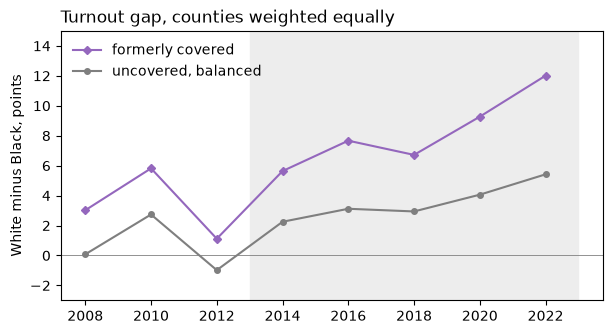

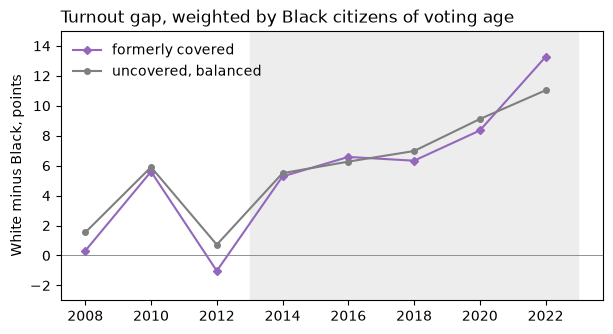

In [24]:
def plot_means(means, title):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(means.index, means.covered, marker="D", ms=4, color="C4", label="formerly covered")
    ax.plot(means.index, means.uncovered, marker="o", ms=4, color="C7", label="uncovered, balanced")
    ax.axhline(0, color="0.5", lw=0.6)
    ax.axvspan(2013, 2023, color="0.93", zorder=0)
    ax.set_xticks(YEARS)
    ax.set_ylim(-3, 15)
    ax.set_title(title, loc="left")
    ax.set_ylabel("White minus Black, points")
    ax.legend(frameon=False)


plot_means(results[("counties equal", "2012")].attrs["means"], "Turnout gap, counties weighted equally")
plot_means(results[("per person", "2012")].attrs["means"], "Turnout gap, weighted by Black citizens of voting age")

With counties weighted equally, the gap in formerly covered counties is wider throughout, and the difference grows after 2012.
Weighted by Black citizens, the two lines are close in every election through 2020; in 2022, the gap in covered places is about 2 points wider.

The difference-in-differences estimate is not the distance between the lines in 2022; it's how much that distance changed relative to 2012.
Weighted by Black citizens, the covered places' gap was about 2 points *narrower* than the comparison's in 2012 and about 2 points wider in 2022, so the estimate for 2022 is about 4.
That's also why balancing on the 2008–2012 gaps, which makes the two lines start together, gives a smaller estimate.

### Checks on the per-person estimate

Is the per-person estimate driven by a few very large counties, or by one state?

In [25]:
cv12 = panel[panel.year == 2012].set_index("GEOID").cvap_Black
checks = {}
for k in [10, 25, 50]:
    q = panel[~panel.GEOID.isin(cv12.sort_values(ascending=False).head(k).index)]
    checks[f"largest {k} counties dropped"] = did(q, "gap_black", balancing_weights(q, "gap_black", per_person=True), reps=0).effect
STATE_ABBR = {"01": "AL", "02": "AK", "04": "AZ", "06": "CA", "12": "FL", "13": "GA", "22": "LA", "26": "MI",
              "28": "MS", "36": "NY", "37": "NC", "45": "SC", "46": "SD", "48": "TX", "51": "VA"}
for st in sorted(FULLY_COVERED | PARTLY_COVERED):
    q = panel[panel.state != st]
    checks[f"without {STATE_ABBR[st]}"] = did(q, "gap_black", balancing_weights(q, "gap_black", per_person=True), reps=0).effect
pd.DataFrame(checks).T[[2022, "average"]].describe().loc[["min", "max"]]

,2022,average
min,2.8,1.3
max,4.6,2.3


Dropping the largest counties or any one covered state moves the per-person average by less than a point (1.3 to 2.3, against 1.9), and the 2022 estimate by about a point (2.8 to 4.6, against 4.0).

### Surveys, through 2024

Section 5 of the Voting Rights Act covered nine states entirely -- Alabama, Alaska, Arizona, Georgia, Louisiana, Mississippi, South Carolina, Texas and Virginia -- and some counties or townships in California, Florida, Michigan, New York, North Carolina and South Dakota.
The voter-file estimates end in 2022; the surveys extend the comparison through 2024, by state rather than county.
We compare the seven Southern states that were covered entirely with the rest of the South, which is the closer comparison; states outside the South, a varied group, show the national trend.
Alaska, Arizona, and the states that were covered only in part are left out, because the survey data don't identify counties.
Michigan, where only two townships were covered, is counted as uncovered.

In [26]:
COVERED_SOUTH = {"AL", "GA", "LA", "MS", "SC", "TX", "VA"}
UNCOVERED_SOUTH = {"AR", "DE", "DC", "KY", "MD", "OK", "TN", "WV"}
LEFT_OUT = {"AK", "AZ", "CA", "FL", "NY", "NC", "SD"}

area = {}
for st in sorted(set(cps.loc[cps.key == "state", "value"])):
    if st in LEFT_OUT:
        continue
    area[st] = ("covered South" if st in COVERED_SOUTH
                else "uncovered South" if st in UNCOVERED_SOUTH
                else "uncovered elsewhere")

cov_cps = group_gaps(cps[cps.rule == "census"], PRES, area)
cov_cps_dropped = group_gaps(cps[cps.rule == "dropped"], PRES, area)
cov_ces = group_gaps(ces, [2008, 2012, 2016, 2020, 2024], area)

table = pd.DataFrame({
    "CPS": change(cov_cps, (2008, 2012), (2020, 2024)),
    "CPS, nonresponse dropped": change(cov_cps_dropped, (2008, 2012), (2020, 2024)),
    "CES (validated)": change(cov_ces, (2008, 2012), (2020, 2024)),
    "CPS, from 2000-2004": change(cov_cps, (2000, 2004), (2020, 2024)),
}).T
table

group,covered South,uncovered South,uncovered elsewhere
CPS,10.9,8.0,11.7
"CPS, nonresponse dropped",11.0,9.2,13.4
CES (validated),8.7,8.1,9.9
"CPS, from 2000-2004",5.6,1.8,5.7


Each entry is the change in the gap, in percentage points: from the average of 2008 and 2012 to the average of 2020 and 2024, or, in the last row, from 2000 and 2004.
The gap widened by similar amounts in all three areas.
In the formerly covered states it widened 1--3 points more than in the rest of the South, and about the same as, or less than, outside the South.

Here's the gap over time in each area, from the CPS.

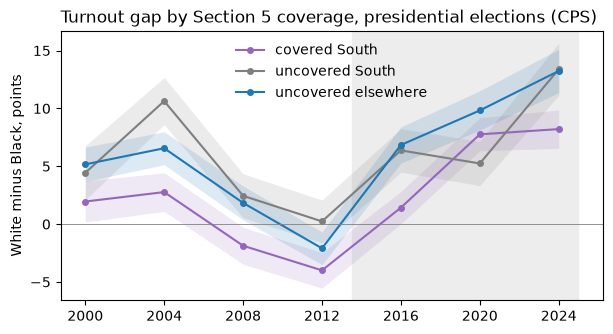

In [27]:
COLORS = {"covered South": "C4", "uncovered South": "C7", "uncovered elsewhere": "C0"}


def plot_groups(gg: pd.DataFrame, years: list[int], order: list[str], title: str, ylabel: str):
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for g in order:
        s = gg[(gg.group == g) & gg.year.isin(years)].set_index("year").sort_index()
        ax.plot(s.index, s.gap, marker="o", ms=4, color=COLORS[g], label=g)
        ax.fill_between(s.index, s.gap - 1.405 * s.se, s.gap + 1.405 * s.se, color=COLORS[g], alpha=0.15, lw=0)
    ax.axhline(0, color="0.5", lw=0.6)
    ax.axvspan(2013.5, years[-1] + 1, color="0.93", zorder=0)
    ax.set_xticks(years)
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False)
    return ax


plot_groups(cov_cps, PRES, ["covered South", "uncovered South", "uncovered elsewhere"],
            "Turnout gap by Section 5 coverage, presidential elections (CPS)",
            "White minus Black, points");

The shaded bands show 84% confidence intervals.
The gray background marks elections after *Shelby County*.

## Summary

The two tests approach the question from different directions.
Part 2 asks what happened when states adopted or dropped substantial restrictions on voting.
Part 3 asks what happened in places that lost federal oversight, whether or not they adopted the restrictions we recorded.
Both find that the changes associated with voting policy were much smaller than the nationwide reopening of the gap, but the estimates in Part 3 depend more on how the comparison is constructed.

Four propositions, with different strengths of evidence:

1. **The gap reopened almost everywhere after 2012** (Part 1).
   This appears in voter files and in both surveys, in every state with a large Black population, and in states that lost preclearance and states that didn't (Part 3).
   The evidence for this is strong.
2. **The statewide restrictions we recorded don't explain much of the reopening** (Part 2).
   When a restriction took effect or ended, overall turnout in the official counts changed by less than a point relative to states whose status didn't change, and so did the gap; the official counts rule out declines in turnout much larger than 2 points, and the voter files rule out effects on the gap much larger than 2.5 points.
   This can't rule out effects of a point or so, effects that build up over several elections, or effects concentrated in some places.
3. **The gap widened somewhat more in formerly covered places, relative to 2012** (Part 3), by an amount that depends on how the comparison is constructed:
   with counties weighted equally, 2–2.6 points of additional widening on average over 2014–2022 and 4–4.5 points by 2022; weighted by Black citizens, little additional widening until 2020 and about 2.5–4 points by 2022; in the surveys through 2024, 1–3 points more widening than in the rest of the South.
   This is reasonably strong descriptive evidence, though the per-person estimates are imprecise.
4. **Ending preclearance caused that additional widening.**
   This is plausible but not established.
   Formerly covered places differ from others in ways that reweighting can't fully remove -- in particular, Obama's effect on Black turnout was largest where Black citizens are concentrated, which is also where coverage was.
   One possibility is that ending preclearance allowed changes in local election administration that a list of statewide restrictions doesn't capture, but these data don't identify the mechanism.

The differences associated with coverage and with restrictions are small compared with the reopening itself, roughly 8–12 points from the Obama years.
That suggests the end of preclearance may have contributed, especially in smaller counties and in recent elections, but it doesn't explain most of the change.
The unusually high Black turnout during Obama's campaigns is a likely part of the explanation, although these data can't rule out other national changes.